In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset('iris')

In [4]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [7]:
df.shape

(150, 5)

In [8]:
df.columns

Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='object')

In [9]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [11]:
df.isnull().sum().sum()

np.int64(0)

In [12]:
df.duplicated().sum()

np.int64(1)

In [14]:
df[df.duplicated(keep=False)]

,sepal_length,sepal_width,petal_length,petal_width,species
101,5.8,2.7,5.1,1.9,virginica
142,5.8,2.7,5.1,1.9,virginica


In [13]:
df.dtypes

,0
sepal_length,float64
sepal_width,float64
petal_length,float64
petal_width,float64
species,object


In [19]:
df_clean = df.drop_duplicates().copy()

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)


Original shape: (150, 5)
Cleaned shape: (149, 5)


In [24]:
df_clean.groupby('species')[[
    'sepal_length',
    'sepal_width',
    'petal_length',
    'petal_width'
]].mean()


,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.006000,3.428000,1.462000,0.246000
versicolor,5.936000,2.770000,4.260000,1.326000
virginica,6.604082,2.979592,5.561224,2.028571


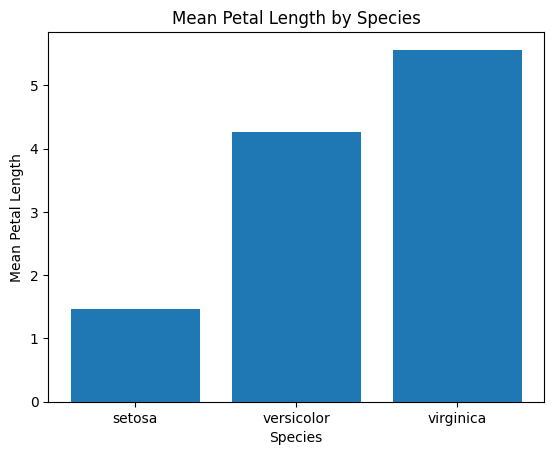

In [25]:
petal_means = df_clean.groupby('species')['petal_length'].mean()

plt.bar(petal_means.index, petal_means.values)
plt.xlabel('Species')
plt.ylabel('Mean Petal Length')
plt.title('Mean Petal Length by Species')
plt.show()

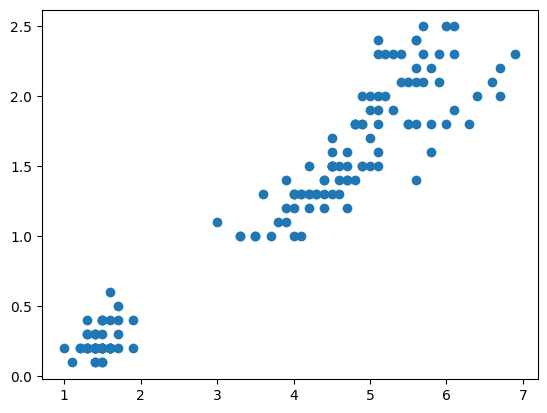

In [26]:
plt.scatter(
    df_clean['petal_length'],
    df_clean['petal_width']
)

In [27]:
df['petal_length'].corr(df['petal_width'])

np.float64(0.9628654314027961)

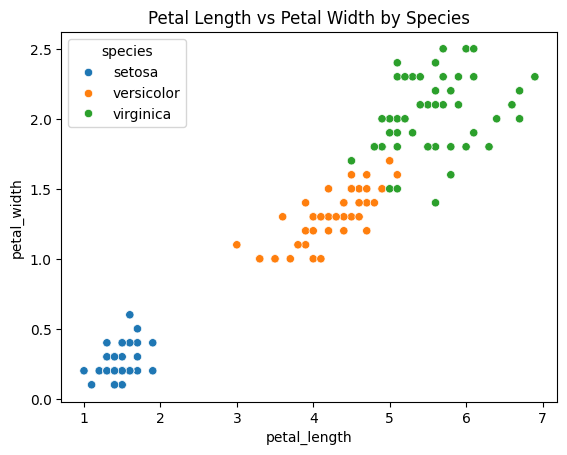

In [28]:

sns.scatterplot(
    data=df_clean,
    x='petal_length',
    y='petal_width',
    hue='species'
)

plt.title('Petal Length vs Petal Width by Species')
plt.show()


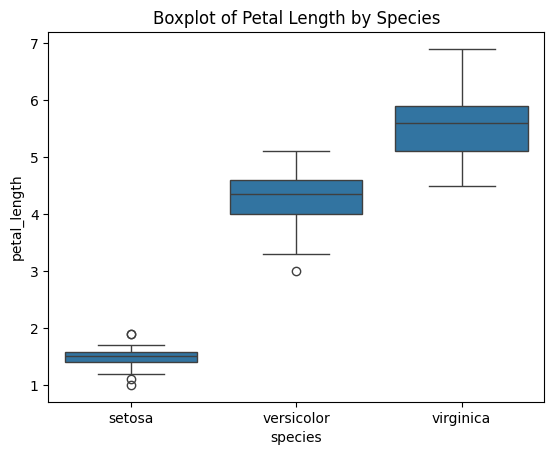

In [29]:
sns.boxplot(
    data=df_clean,
    x='species',
    y='petal_length'
)

plt.title('Boxplot of Petal Length by Species')
plt.show()

## Key Findings — Iris Flower EDA

**1. Differences in petal length across species**

The group-wise mean analysis showed that Virginica had the highest average petal length (approximately 5.56), whereas Setosa had the lowest (approximately 1.46). Versicolor fell between the two species.

**2. Strong positive relationship between petal length and petal width**

The scatter plot showed an upward trend between petal length and petal width. The Pearson correlation coefficient was approximately 0.963, indicating a very strong positive linear association across the observations. The species-coloured scatter plot also revealed clear separation of Setosa from the other species, with some overlap between Versicolor and Virginica.

**3. Differences in petal-length distributions**

The box plot showed that Virginica had the highest median petal length, while Setosa had the lowest. Potential outliers were flagged for Setosa and Versicolor under the box plot's default rule. These observations should be investigated before deciding whether any data cleaning is necessary.